# **Modèles Génératifs avec PyTorch**
**Pr. Mohamed YOUSSFI, ENSET Université Hassan II de Casablanca**

## 0. Préparation de l'environnement

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

PyTorch : 2.11.0+cu130
Device : cuda


# **1. Jeu de données MNIST**

MNIST contient des images de chiffres manuscrits de taille :

28 x 28 = 784

Chaque image possède un label entre 0 et 9.

Nous utiliserons le **même dataset** pour comparer plusieurs paradigmes d'apprentissage.

- https://ossci-datasets.s3.amazonaws.com/mnist/train-images-idx3-ubyte.gz
- https://ossci-datasets.s3.amazonaws.com/mnist/train-labels-idx1-ubyte.gz
- https://ossci-datasets.s3.amazonaws.com/mnist/t10k-images-idx3-ubyte.gz
- https://ossci-datasets.s3.amazonaws.com/mnist/t10k-labels-idx1-ubyte.gz

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Train :", len(train_dataset))
print("Test  :", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.59MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.3MB/s]

Train : 60000
Test  : 10000


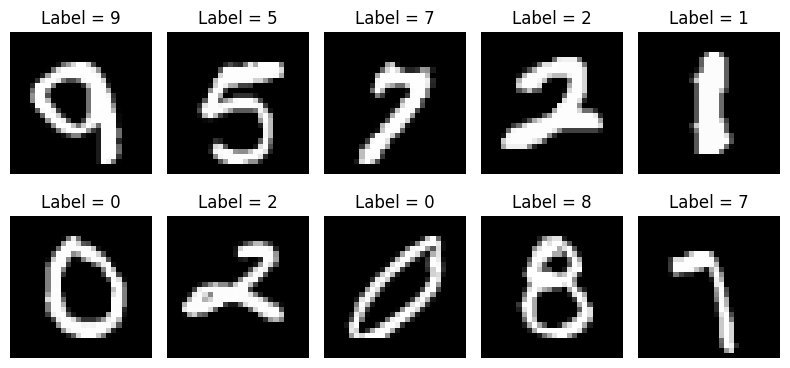

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# **Partie I — Modèle discriminatif**

# **2. Classification : apprendre \(P(y|x)\)**

Un classifieur reçoit une entrée \(x\) et prédit une classe \(y\).
$$
\
x \longrightarrow \text{Réseau de neurones} \longrightarrow \hat y
\
$$
L'objectif est d'apprendre approximativement :
$$
\
P(y|x)
\
$$
Nous allons utiliser un réseau entièrement connecté simple.

In [4]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier

Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

### Fonction de perte

Pour une classification multi-classe, nous utilisons :
$$
\
\mathcal{L}_{class} = CrossEntropy(\hat y, y)
\
$$

Le label est donc indispensable.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(classifier.parameters(), lr=1e-3)

In [6]:
def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_classifier(classifier, train_loader, epochs=3)

Epoch 1/3 - Loss = 0.4211
Epoch 2/3 - Loss = 0.1964
Epoch 3/3 - Loss = 0.1418


In [7]:
def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total

accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100*accuracy:.2f}%")

Accuracy = 96.26%


Une autre façon pour évaluer le modèle

In [8]:
!pip install torcheval

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.2/179.2 kB 16.9 MB/s eta 0:00:00


In [9]:
from torcheval.metrics import MulticlassAccuracy

@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()
    device = next(model.parameters()).device

    metric = MulticlassAccuracy(device=device)

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        metric.update(logits, y)

    return metric.compute().item()


accuracy = evaluate_classifier(classifier, test_loader)
print(f"Accuracy = {100 * accuracy:.2f}%")

Accuracy = 96.26%


Le réseau apprend ici :

x => y

Il **discrimine** les classes.

Il ne sait pas générer une nouvelle image de chiffre.

# **Partie II — Autoencodeur**

# **3. Idée générale**

Un autoencodeur apprend à reconstruire son entrée :

x \rightarrow Encoder \rightarrow z \rightarrow Decoder \rightarrow \hat x
 x -> Encoder -> z -> Decoder -> xhat

avec : xhat approxime x


Le vecteur z est une **représentation latente** de l'entrée.

L'apprentissage devient : x -> x

Les labels ne sont plus nécessaires.

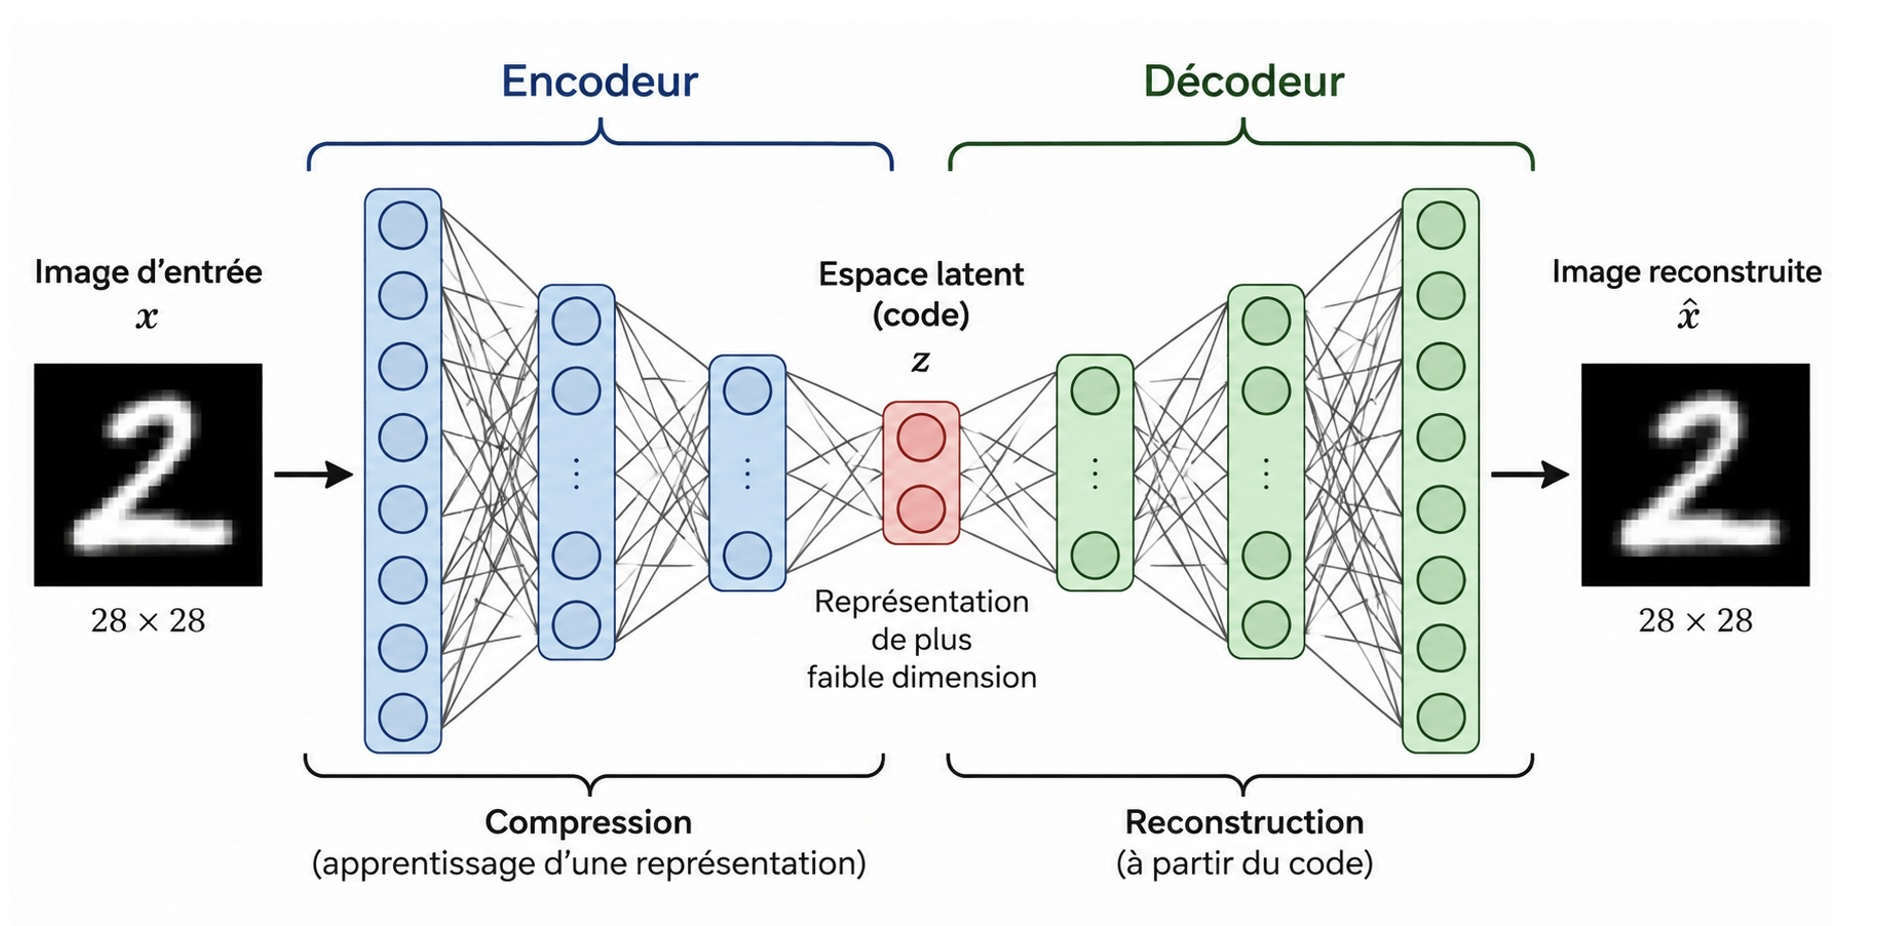

In [10]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

ae = Autoencoder(latent_dim=2).to(device)
ae

Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

# **4. Loss de reconstruction**

Nous utilisons ici :
$$
\
\mathcal{L}_{rec}=\frac{1}{N}\sum_{i=1}^{N}(x_i-\hat{x}_i)^2
\
$$
avec `MSELoss`.

In [11]:
ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.Adam(ae.parameters(), lr=1e-3)
def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0661
Epoch 2/5 - Loss = 0.0520
Epoch 3/5 - Loss = 0.0490
Epoch 4/5 - Loss = 0.0469
Epoch 5/5 - Loss = 0.0454


# **5. Visualisation des reconstructions**

La première ligne montre les images originales.

La deuxième ligne montre les images reconstruites.

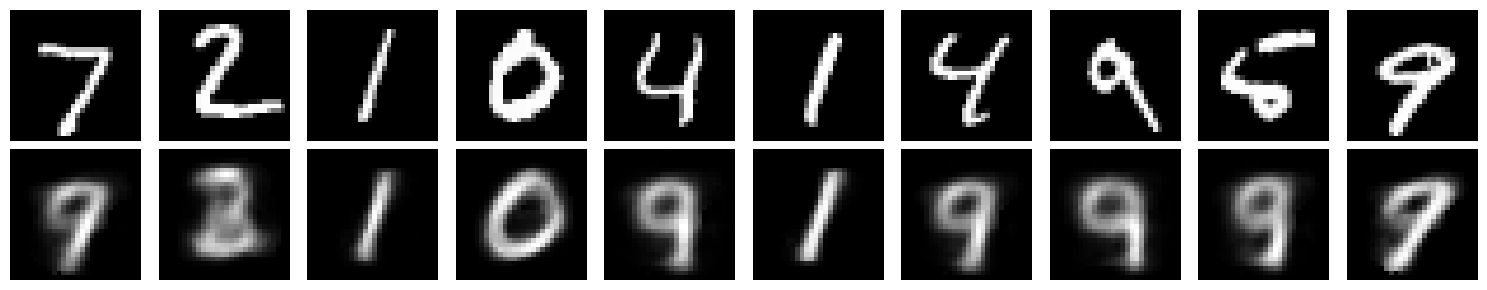

In [12]:
ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show()

# **6. Visualisation de l'espace latent**

Nous avons volontairement choisi :

```python
latent_dim = 2
```

Nous pouvons donc représenter chaque image MNIST par un point dans un plan.

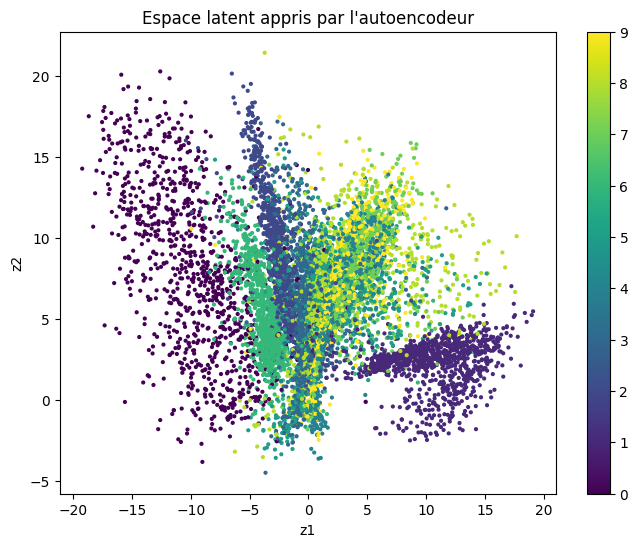

In [13]:
## Visualisation de l'espace latent
ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(Z[:, 0], Z[:, 1], c=Y, s=4)
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

## Génération à partir d'un chiffre connu

In [15]:
import torch
import matplotlib.pyplot as plt

@torch.no_grad()
def generer_chiffre(model, dataloader, chiffre):
    if chiffre not in range(10):
        raise ValueError("Le chiffre doit être compris entre 0 et 9.")

    device = next(model.parameters()).device
    model.eval()

    somme_z = None
    nombre = 0

    for images, labels in dataloader:
        # Sélection des images du chiffre demandé
        images = images[labels == chiffre]

        if images.shape[0] == 0:
            continue

        z = model.encode(images.to(device))

        if somme_z is None:
            somme_z = z.sum(dim=0, keepdim=True)
        else:
            somme_z += z.sum(dim=0, keepdim=True)

        nombre += z.shape[0]

    if nombre == 0:
        raise ValueError(f"Aucune image du chiffre {chiffre} trouvée.")

    z_moyen = somme_z / nombre
    return model.decode(z_moyen).cpu()

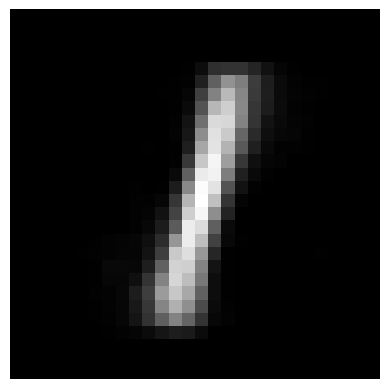

In [16]:
# model : ton autoencodeur entraîné
# train_loader : ton DataLoader MNIST
image = generer_chiffre(ae, train_loader, chiffre=1)

plt.imshow(image[0, 0].numpy(), cmap="gray")
plt.axis("off")
plt.show()

# **7. Limite d'un autoencodeur classique**

L'AE apprend des représentations utiles, mais rien ne garantit que l'espace latent soit :

- continu ;
- régulier ;
- facile à échantillonner ;
- distribué selon une loi connue.

Si nous choisissons arbitrairement un point :
$$
\
z=(z_1,z_2)
\
$$
le décodeur peut produire une image peu réaliste.

Cette difficulté motive le **Variational Autoencoder**.

# **Partie III — Variational Autoencoder (VAE)**

# **8. Principe**

Au lieu d'associer une entrée \(x\) à un point latent unique, le VAE associe \(x\) à une distribution :
$$
\
q(z|x)=\mathcal{N}(\mu,\sigma^2)
\
$$
L'encodeur produit :
$$
\
\mu(x)
\
$$
et :
$$
\
\log \sigma^2(x)
\
$$
Puis nous échantillonnons \(z\).

# **9. Reparameterization trick**

On veut échantillonner :
$$
\
z \sim \mathcal{N}(\mu,\sigma^2)
\
$$

tout en conservant la rétropropagation.

On écrit :
$$
\
\epsilon \sim \mathcal{N}(0,I)
\
$$
puis :
$$
\
\boxed{
z=\mu+\sigma\odot\epsilon
}
\
$$

C'est le **reparameterization trick**.

In [17]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

# **10. Loss et entrainement du VAE**

Le VAE combine deux termes :

### Reconstruction
$$
\
\mathcal{L}_{rec}
\
$$

### Régularisation de l'espace latent
$$
\
D_{KL}
\left(
q(z|x)
\parallel
\mathcal N(0,I)
\right)
\
$$

Pour une gaussienne diagonale :
$$
\
D_{KL}
=
-\frac12
\sum
\left(
1+\log\sigma^2-\mu^2-\sigma^2
\right)
\
$$

La loss totale est :
$$
\
\boxed{
\mathcal L_{VAE}
=
\mathcal L_{rec}
+
\beta D_{KL}
}
\
$$

In [18]:
def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [19]:
## Entrainement
vae_optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)
def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        total_rec = 0
        total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(
                x_hat,
                x,
                mu,
                logvar,
                beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | "
            f"KL={total_kl/n:.2f}"
        )

train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=196.60 | Rec=193.24 | KL=3.37
Epoch 2/20 | Loss=165.83 | Rec=160.80 | KL=5.04
Epoch 3/20 | Loss=159.14 | Rec=153.65 | KL=5.50
Epoch 4/20 | Loss=155.56 | Rec=149.86 | KL=5.71
Epoch 5/20 | Loss=153.28 | Rec=147.47 | KL=5.81
Epoch 6/20 | Loss=151.34 | Rec=145.42 | KL=5.92
Epoch 7/20 | Loss=149.91 | Rec=143.89 | KL=6.02
Epoch 8/20 | Loss=148.68 | Rec=142.60 | KL=6.08
Epoch 9/20 | Loss=147.69 | Rec=141.56 | KL=6.14
Epoch 10/20 | Loss=146.88 | Rec=140.71 | KL=6.18
Epoch 11/20 | Loss=146.00 | Rec=139.76 | KL=6.23
Epoch 12/20 | Loss=145.30 | Rec=139.02 | KL=6.28
Epoch 13/20 | Loss=144.85 | Rec=138.54 | KL=6.31
Epoch 14/20 | Loss=144.23 | Rec=137.88 | KL=6.35
Epoch 15/20 | Loss=143.59 | Rec=137.20 | KL=6.39
Epoch 16/20 | Loss=143.32 | Rec=136.92 | KL=6.40
Epoch 17/20 | Loss=142.82 | Rec=136.39 | KL=6.43
Epoch 18/20 | Loss=142.57 | Rec=136.12 | KL=6.45
Epoch 19/20 | Loss=142.21 | Rec=135.72 | KL=6.49
Epoch 20/20 | Loss=141.74 | Rec=135.24 | KL=6.50


# **11. Reconstruction avec le VAE**

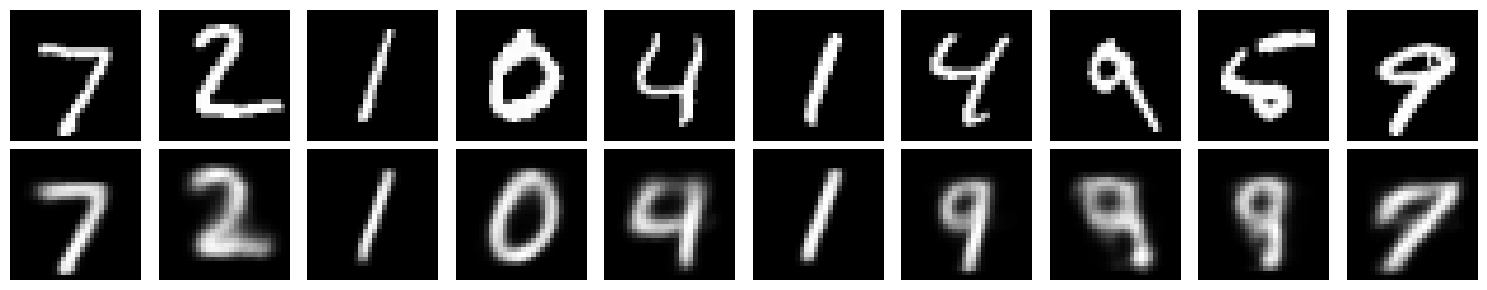

In [20]:
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.tight_layout()
plt.show()

# **12. Visualisation de l'espace latent du VAE**

Nous utilisons ici le vecteur moyen \(\mu\) comme représentation latente.

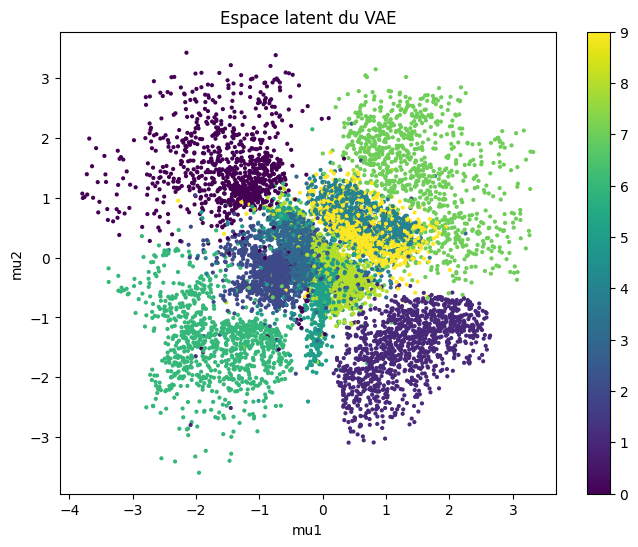

In [21]:
vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=4
)

plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()

## 13. Générer de nouvelles images

C'est le point essentiel.

Nous n'avons maintenant plus besoin d'une image d'entrée.

Nous échantillonnons directement :
$$
\
z \sim \mathcal N(0,I)
\
$$

puis :
$$
\
x_{new}=Decoder(z)
\
$$

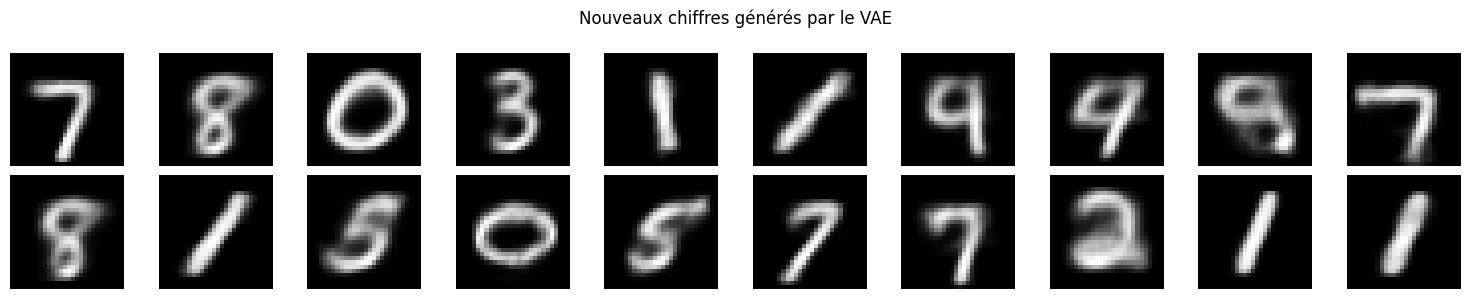

In [22]:
# Générer de nouvelles images
vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()

## 14. Explorer manuellement l'espace latent

Avec un espace latent 2D, nous pouvons construire une grille de points et observer les images produites par le décodeur.

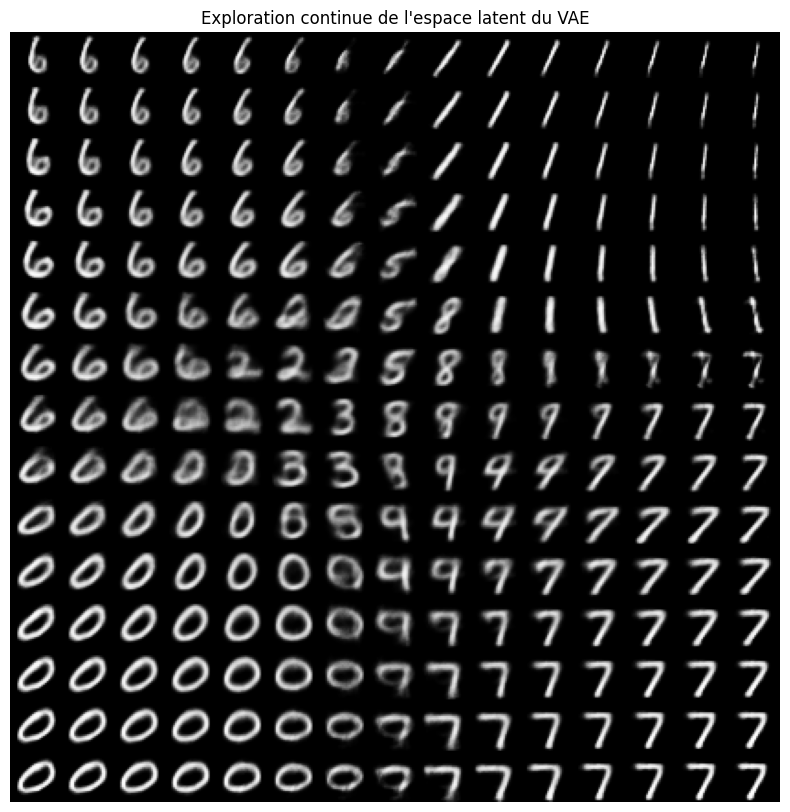

In [23]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):

            z = torch.tensor(
                [[xi, yi]],
                dtype=torch.float32,
                device=device
            )

            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            figure[
                i*28:(i+1)*28,
                j*28:(j+1)*28
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()

# **Partie IV — Generative Adversarial Networks**

## 15. Principe des GAN

# Comprendre le principe des GANs

Un **GAN** (*Generative Adversarial Network*), ou **réseau antagoniste génératif**, apprend à produire de nouvelles données ressemblant à celles d’un jeu d’entraînement.

Il repose sur deux réseaux entraînés avec des objectifs opposés :

- le **générateur**, qui crée de fausses données ;
- le **discriminateur**, qui apprend à distinguer les données réelles des données générées.

> **Analogie :** le générateur joue le rôle d’un faussaire, tandis que le discriminateur joue celui d’un expert chargé de détecter les contrefaçons. Chacun pousse l’autre à progresser.

---

## 1. Schéma d’architecture

```text
   Bruit aléatoire z
          │
          ▼
   ┌─────────────┐
   │ Générateur G│
   └──────┬──────┘
          │
          ▼
    Image générée ───────────┐
                             │
                             ▼
                      ┌─────────────────┐
                      │ Discriminateur D│
                      └────────┬────────┘
                             ▲ │
                             │ ▼
    Image réelle ────────────┘ Score « réel »
          ▲                    entre 0 et 1
          │
   Jeu d’entraînement
```

Le discriminateur reçoit une image réelle **ou** une image générée et produit un score :

- proche de **1** : il considère l’image comme réelle ;
- proche de **0** : il considère l’image comme générée.

Ce schéma décrit le GAN classique ; certaines variantes utilisent d’autres types de scores.

---

## 2. Le générateur : créer des images

Le générateur transforme un vecteur aléatoire `z` en une image :

$$
\hat{x} = G(z)
$$

```text
Vecteur aléatoire → Générateur → Image synthétique
```

Le vecteur `z` est souvent tiré dans une loi normale standard :

$$
z \sim \mathcal{N}(0, I)
$$

Au début, les images produites sont généralement peu structurées. Pendant l’entraînement, le générateur apprend à produire des images que le discriminateur considère comme réelles.

> Dans un GAN classique, le générateur ne cherche pas à reconstruire une image précise : il cherche à imiter la distribution des données d’entraînement.

---

## 3. Le discriminateur : distinguer réel et généré

Le discriminateur reçoit :

- des images réelles issues du jeu d’entraînement ;
- des images synthétiques produites par le générateur.

Il apprend à attribuer les bonnes réponses :

| Entrée | Réponse souhaitée pour le discriminateur |
|---|---|
| Image réelle `x` | `1` : réelle |
| Image générée `G(z)` | `0` : générée |

Son objectif est donc de **repérer les erreurs du générateur**.

---

## 4. Comment se déroule l’entraînement ?

On alterne généralement deux étapes.

### Étape A — Entraîner le discriminateur

On lui présente des images réelles et générées, puis on ajuste ses paramètres pour améliorer sa classification.

```text
Images réelles   → D → objectif : 1
Images générées  → D → objectif : 0
```

Pendant cette étape, **les paramètres du générateur ne sont pas mis à jour**.

### Étape B — Entraîner le générateur

On crée de nouvelles images, puis on les fait évaluer par le discriminateur.

Le générateur cherche à obtenir un score « réel » élevé :

```text
Bruit z → G → Image générée → D → objectif du générateur : 1
```

Pendant cette étape :

- les paramètres du discriminateur restent fixes ;
- les gradients traversent néanmoins le discriminateur pour ajuster le générateur.

```text
Retour d’apprentissage :

Erreur → Discriminateur → Générateur
                              ↑
                   Paramètres mis à jour
```

> Le discriminateur fournit ainsi un signal d’apprentissage au générateur, sans qu’il soit nécessaire de lui donner une image cible pour chaque vecteur aléatoire.

---

## 5. Pourquoi parle-t-on d’apprentissage « antagoniste » ?

Les deux réseaux poursuivent des objectifs opposés :

| Réseau | Objectif |
|---|---|
| Générateur | Faire passer ses images pour des images réelles |
| Discriminateur | Détecter les images générées |

Idéalement, le générateur finit par produire des données dont la distribution correspond à celle des données réelles.

À cet équilibre théorique, le discriminateur ne peut plus les distinguer et attribue un score de `0.5`.

> Un score proche de `0.5` ne prouve cependant pas, à lui seul, que le générateur est bon : le discriminateur peut aussi être insuffisamment entraîné.

---

## 6. Générer des images après l’entraînement

Une fois l’entraînement terminé, **seul le générateur est nécessaire** :

```text
Nouveau vecteur aléatoire → Générateur entraîné → Nouvelle image
```

Le discriminateur a servi à guider l’apprentissage, mais il n’est plus indispensable pour produire des images.

---

## 7. Différence essentielle avec un VAE

| VAE | GAN classique |
|---|---|
| Utilise un encodeur et un décodeur | Utilise un générateur et un discriminateur |
| Apprend à reconstruire des entrées et régularise l’espace latent | Apprend à produire des données capables de tromper le discriminateur |
| Utilise une perte de reconstruction et un terme KL | Utilise un objectif adversarial |

Les GANs peuvent produire des images très réalistes, mais leur entraînement peut être instable. Ils peuvent aussi manquer de diversité et produire toujours des exemples similaires : c’est le **mode collapse**.

## À retenir

**Un GAN apprend à générer des données grâce à une compétition : le générateur cherche à tromper le discriminateur, tandis que le discriminateur apprend à détecter ses productions.**

# Implémentation d’un GAN avec PyTorch sur MNIST

## Objectif

Nous allons entraîner un **Generative Adversarial Network (GAN)** pour générer des images de chiffres manuscrits.

Un GAN contient deux réseaux :

- **Le générateur** transforme un vecteur aléatoire en image.
- **Le discriminateur** apprend à distinguer les vraies images des images générées.

Les deux réseaux apprennent en compétition : le générateur cherche à tromper le discriminateur, tandis que le discriminateur cherche à détecter les images artificielles.

> Ce modèle utilise des couches entièrement connectées. Il ne s’agit pas d’un GAN convolutif.

---

## 1. Préparation des données

Nous utilisons le jeu de données **MNIST**, composé d’images de chiffres manuscrits en niveaux de gris.

Chaque image possède :

- un seul canal ;
- une hauteur de 28 pixels ;
- une largeur de 28 pixels.

Un lot d’images possède donc la forme :

`[taille_du_lot, 1, 28, 28]`

### Transformation des pixels

`ToTensor()` transforme les images en tenseurs dont les valeurs sont comprises entre 0 et 1.

`Normalize((0.5,), (0.5,))` applique ensuite :

\[
x_{\text{normalisé}} = \frac{x - 0.5}{0.5}
\]

Les pixels sont alors compris entre **−1 et 1**.

Cette transformation est importante : le générateur utilise une fonction `Tanh` en sortie, qui produit également des valeurs dans cet intervalle.

### Chargement par lots

Le `DataLoader` regroupe les images en lots et mélange les données avec `shuffle=True`.

Les étiquettes MNIST ne sont pas utilisées : ce GAN apprend à générer des chiffres sans recevoir leur classe.

---

In [24]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

# Facilite la reproductibilité, sans la garantir sur tous les matériels.
torch.manual_seed(42)

# Utiliser le GPU CUDA s'il est disponible.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
image_dim = 28 * 28
batch_size = 128
epochs = 20
learning_rate = 0.0002

output_dir = Path("images_generees")
output_dir.mkdir(exist_ok=True)

print(f"Appareil utilisé : {device}")

Appareil utilisé : cuda


**Explications :**
- latent_dim = 100 : chaque image sera générée à partir d’un vecteur aléatoire de 100 nombres.
- image_dim = 784 : une image MNIST mesure (28 \times 28) pixels en niveaux de gris.
- batch_size = 128 : les réseaux traitent jusqu’à 128 images à chaque itération.
- epochs = 20 : l’entraînement parcourt 20 fois le jeu de données.
- learning_rate : contrôle l’amplitude des mises à jour des paramètres.

In [25]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
)

## 2. Le générateur

Le générateur transforme un vecteur de bruit en image.

Son entrée contient **100 nombres aléatoires**, tirés dans une distribution normale standard.

Son architecture suit le chemin :

**100 → 256 → 512 → 784**

Les 784 valeurs finales correspondent aux pixels d’une image :

\[
784 = 28 \times 28
\]

### Fonctions d’activation

- `LeakyReLU` introduit une non-linéarité et conserve une petite pente pour les valeurs négatives.
- `Tanh` limite les valeurs finales à l’intervalle **[−1, 1]**.

L’opération `view` réorganise ensuite les pixels pour obtenir des images de forme :

`[taille_du_lot, 1, 28, 28]`

> Le générateur ne reçoit pas une image à reconstruire : il apprend à créer une image à partir du bruit.

---

In [26]:
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, image_dim),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.network(noise)


generator = Generator(latent_dim).to(device)

## 3. Le discriminateur

Le discriminateur reçoit une image et produit un score unique.

Son architecture suit le chemin :

**784 → 512 → 256 → 1**

La couche `Flatten` transforme chaque image en un vecteur de 784 pixels.

Le score final est un **logit**, c’est-à-dire un score brut :

- un score élevé indique une prédiction plutôt « réelle » ;
- un score faible indique une prédiction plutôt « artificielle ».

### Pourquoi ne pas ajouter de sigmoid ?

Nous utilisons `BCEWithLogitsLoss`.

Cette fonction combine la sigmoid et l’entropie croisée binaire de manière numériquement stable.

Il ne faut donc pas ajouter une seconde sigmoid avant cette perte.

---

In [27]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(image_dim, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1),
        )

    def forward(self, images):
        return self.network(images)


discriminator = Discriminator().to(device)

## 4. Les optimiseurs

Chaque réseau possède son propre optimiseur Adam :

- `optimizer_g` met à jour le générateur ;
- `optimizer_d` met à jour le discriminateur.

Cette séparation permet d’entraîner alternativement les deux réseaux.

Un vecteur `fixed_noise` est également créé pour la visualisation.

En conservant le même bruit d’une époque à l’autre, nous pouvons observer comment les images associées à ces mêmes entrées évoluent.

---

In [28]:
criterion = nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(
    generator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

optimizer_d = torch.optim.Adam(
    discriminator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

In [29]:
# Même bruit à chaque époque pour comparer les résultats.
fixed_noise = torch.randn(64, latent_dim, device=device)

for epoch in range(epochs):
    generator.train()
    discriminator.train()

    total_loss_d = 0.0
    total_loss_g = 0.0

    for real_images, _ in loader:
        # [B, 1, 28, 28] -> [B, 784]
        real_images = real_images.to(device).flatten(start_dim=1)

        # Le dernier lot peut contenir moins de 128 images.
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(
            current_batch_size, 1, device=device
        )
        fake_labels = torch.zeros(
            current_batch_size, 1, device=device
        )

        # =====================================
        # A. Entraîner le discriminateur
        # =====================================
        discriminator.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)

        # Évaluer les vraies images.
        real_scores = discriminator(real_images)
        loss_real = criterion(real_scores, real_labels)

        # Créer de fausses images à partir de bruit.
        noise = torch.randn(
            current_batch_size, latent_dim, device=device
        )
        fake_images = generator(noise)

        # Couper le gradient vers G pendant cette étape.
        fake_scores = discriminator(fake_images.detach())
        loss_fake = criterion(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2

        loss_d.backward()
        optimizer_d.step()

        # =====================================
        # B. Entraîner le générateur
        # =====================================
        discriminator.requires_grad_(False)
        optimizer_g.zero_grad(set_to_none=True)

        # Nouvelle évaluation avec D qui vient d'être mis à jour.
        fake_scores = discriminator(fake_images)

        # G veut que ses images soient classées "réelles".
        loss_g = criterion(fake_scores, real_labels)

        loss_g.backward()
        optimizer_g.step()

        total_loss_d += loss_d.item()
        total_loss_g += loss_g.item()

    print(
        f"Époque {epoch + 1:02d}/{epochs} | "
        f"Loss D : {total_loss_d / len(loader):.4f} | "
        f"Loss G : {total_loss_g / len(loader):.4f}"
    )

    # =====================================
    # C. Sauvegarder des exemples
    # =====================================
    generator.eval()

    with torch.no_grad():
        samples = generator(fixed_noise)
        samples = samples.view(-1, 1, 28, 28)

        # [-1, 1] -> [0, 1] pour enregistrer les images.
        samples = (samples + 1) / 2

        save_image(
            samples,
            output_dir / f"epoch_{epoch + 1:03d}.png",
            nrow=8,
        )

# Sauvegarder les paramètres appris.
torch.save(generator.state_dict(), "generator_mnist.pt")

Époque 01/20 | Loss D : 0.4336 | Loss G : 1.4538
Époque 02/20 | Loss D : 0.3408 | Loss G : 2.2766
Époque 03/20 | Loss D : 0.3076 | Loss G : 2.4908
Époque 04/20 | Loss D : 0.3074 | Loss G : 2.6254
Époque 05/20 | Loss D : 0.3141 | Loss G : 2.4900
Époque 06/20 | Loss D : 0.2992 | Loss G : 2.5974
Époque 07/20 | Loss D : 0.2969 | Loss G : 2.8471
Époque 08/20 | Loss D : 0.2992 | Loss G : 2.4814
Époque 09/20 | Loss D : 0.2591 | Loss G : 2.7787
Époque 10/20 | Loss D : 0.2540 | Loss G : 2.8553
Époque 11/20 | Loss D : 0.2851 | Loss G : 2.8265
Époque 12/20 | Loss D : 0.3097 | Loss G : 2.4813
Époque 13/20 | Loss D : 0.3245 | Loss G : 2.2654
Époque 14/20 | Loss D : 0.3326 | Loss G : 2.1851
Époque 15/20 | Loss D : 0.3483 | Loss G : 2.1116
Époque 16/20 | Loss D : 0.3800 | Loss G : 1.9155
Époque 17/20 | Loss D : 0.3984 | Loss G : 1.7582
Époque 18/20 | Loss D : 0.4278 | Loss G : 1.6476
Époque 19/20 | Loss D : 0.4424 | Loss G : 1.5616
Époque 20/20 | Loss D : 0.4511 | Loss G : 1.5243


## 7. Visualiser les résultats

Après chaque époque, nous utilisons le même bruit de référence pour générer des images.

`torch.no_grad()` convient ici, car nous souhaitons uniquement observer les résultats, sans entraîner le modèle.

Les images sont ramenées dans l’intervalle **[0, 1]** :
$$
\
x_{\text{affiché}} = \frac{x_{\text{généré}} + 1}{2}
\
$$

`make_grid` rassemble plusieurs images dans une grille.

`permute(1, 2, 0)` adapte l’ordre des dimensions pour l’affichage avec Matplotlib.

---


In [30]:
# Générer des images
generator.eval()

with torch.no_grad():
    new_noise = torch.randn(16, latent_dim, device=device)

    new_images = generator(new_noise)
    new_images = new_images.view(-1, 1, 28, 28)
    new_images = (new_images + 1) / 2

    save_image(
        new_images,
        output_dir / "nouveaux_chiffres.png",
        nrow=4,
    )

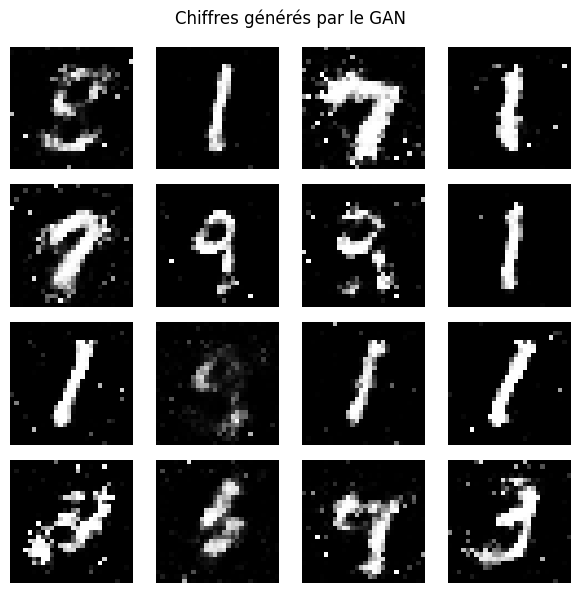

In [31]:
# Générer et visualiser des images
import matplotlib.pyplot as plt
import torch

# Mode évaluation
generator.eval()

# Générer 16 images sans calculer de gradients
with torch.no_grad():
    noise = torch.randn(16, latent_dim, device=device)
    images = generator(noise)

    # [16, 784] -> [16, 1, 28, 28]
    images = images.reshape(-1, 1, 28, 28)

    # Convertir les pixels de [-1, 1] vers [0, 1]
    images = ((images + 1) / 2).clamp(0, 1)

    # Matplotlib utilise les données sur CPU
    images = images.cpu()

# Afficher une grille de 4 × 4
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

fig.suptitle("Chiffres générés par le GAN")
plt.tight_layout()
plt.show()

## 8. Générer de nouvelles images

Après l’entraînement :

1. nous tirons de nouveaux vecteurs aléatoires ;
2. nous les transmettons au générateur ;
3. nous affichons les images obtenues.

**Le discriminateur n’est plus nécessaire pour générer des images.**

Ce GAN n’est pas conditionnel : nous ne pouvons pas lui demander explicitement de produire un chiffre particulier.

Pour choisir la classe à générer, il faudrait utiliser un **GAN conditionnel**.

---

## 9. Interpréter l’apprentissage

Les pertes d’un GAN ne diminuent pas nécessairement de manière régulière, car les deux réseaux poursuivent des objectifs opposés.

Il faut donc aussi observer :

- la qualité visuelle des images ;
- leur diversité ;
- l’évolution au fil des époques.

Un problème possible est le **mode collapse** : le générateur produit seulement quelques types d’images, même lorsque le bruit varie.

> En résumé : le discriminateur apprend à reconnaître les faux, et le générateur apprend à fabriquer des faux plus convaincants.

# Code Complet du GAN

Époque 01/20 | Loss D : 0.4336 | Loss G : 1.4538
Époque 02/20 | Loss D : 0.3408 | Loss G : 2.2766
Époque 03/20 | Loss D : 0.3076 | Loss G : 2.4908
Époque 04/20 | Loss D : 0.3074 | Loss G : 2.6254
Époque 05/20 | Loss D : 0.3141 | Loss G : 2.4900
Époque 06/20 | Loss D : 0.2992 | Loss G : 2.5974
Époque 07/20 | Loss D : 0.2969 | Loss G : 2.8471
Époque 08/20 | Loss D : 0.2992 | Loss G : 2.4814
Époque 09/20 | Loss D : 0.2591 | Loss G : 2.7787
Époque 10/20 | Loss D : 0.2540 | Loss G : 2.8553
Époque 11/20 | Loss D : 0.2851 | Loss G : 2.8265
Époque 12/20 | Loss D : 0.3097 | Loss G : 2.4813
Époque 13/20 | Loss D : 0.3245 | Loss G : 2.2654
Époque 14/20 | Loss D : 0.3326 | Loss G : 2.1851
Époque 15/20 | Loss D : 0.3483 | Loss G : 2.1116
Époque 16/20 | Loss D : 0.3800 | Loss G : 1.9155
Époque 17/20 | Loss D : 0.3984 | Loss G : 1.7582
Époque 18/20 | Loss D : 0.4278 | Loss G : 1.6476
Époque 19/20 | Loss D : 0.4424 | Loss G : 1.5616
Époque 20/20 | Loss D : 0.4511 | Loss G : 1.5243


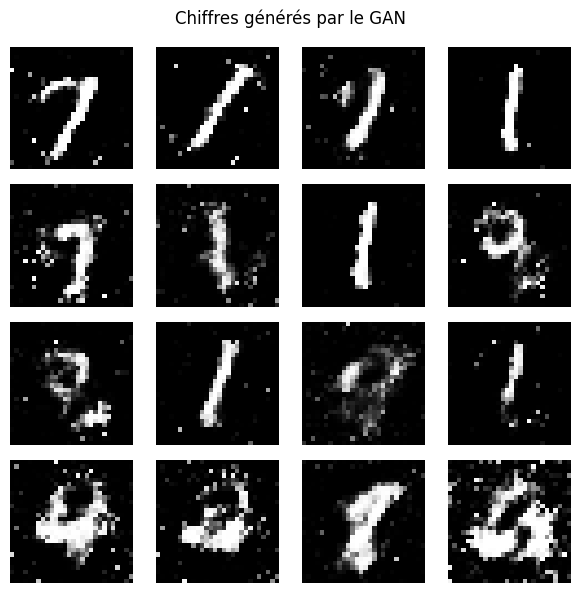

In [32]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

# -------------------------
# Configuration
# -------------------------
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
batch_size = 128
epochs = 20
learning_rate = 2e-4

output_dir = Path("images_generees")
output_dir.mkdir(exist_ok=True)

# -------------------------
# Données : images de 28 × 28
# -------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    # Passage de [0, 1] à [-1, 1], comme la sortie du générateur
    transforms.Normalize((0.5,), (0.5,)),
])

dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=transform,
)

loader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
)

# -------------------------
# Générateur : bruit -> image
# -------------------------
generator = nn.Sequential(
    nn.Linear(latent_dim, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 28 * 28),
    nn.Tanh(),  # Pixels dans [-1, 1]
).to(device)

# -------------------------
# Discriminateur : image -> score
# -------------------------
discriminator = nn.Sequential(
    nn.Linear(28 * 28, 512),
    nn.LeakyReLU(0.2),

    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),

    nn.Linear(256, 1),
    # Pas de Sigmoid : inclus dans BCEWithLogitsLoss
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(
    generator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

optimizer_d = torch.optim.Adam(
    discriminator.parameters(),
    lr=learning_rate,
    betas=(0.5, 0.999),
)

# Même bruit à chaque époque pour visualiser la progression
fixed_noise = torch.randn(64, latent_dim, device=device)

# -------------------------
# Entraînement
# -------------------------
for epoch in range(epochs):
    total_loss_d = 0.0
    total_loss_g = 0.0

    for real_images, _ in loader:
        real_images = real_images.to(device).view(-1, 28 * 28)
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(current_batch_size, 1, device=device)
        fake_labels = torch.zeros(current_batch_size, 1, device=device)

        # 1. Entraîner le discriminateur
        discriminator.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)

        real_scores = discriminator(real_images)
        loss_real = criterion(real_scores, real_labels)

        noise = torch.randn(current_batch_size, latent_dim, device=device)
        fake_images = generator(noise)

        # detach() empêche de modifier le générateur pendant cette étape
        fake_scores = discriminator(fake_images.detach())
        loss_fake = criterion(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2
        loss_d.backward()
        optimizer_d.step()

        # 2. Entraîner le générateur
        # On fige les paramètres de D, mais on garde le gradient vers G.
        discriminator.requires_grad_(False)
        optimizer_g.zero_grad(set_to_none=True)

        fake_scores = discriminator(fake_images)

        # G cherche à faire classer ses images comme "vraies".
        loss_g = criterion(fake_scores, real_labels)

        loss_g.backward()
        optimizer_g.step()

        total_loss_d += loss_d.item()
        total_loss_g += loss_g.item()

    print(
        f"Époque {epoch + 1:02d}/{epochs} | "
        f"Loss D : {total_loss_d / len(loader):.4f} | "
        f"Loss G : {total_loss_g / len(loader):.4f}"
    )

    # Sauvegarder une grille de 64 images
    generator.eval()
    with torch.no_grad():
        samples = generator(fixed_noise).view(-1, 1, 28, 28)

        # Repasser de [-1, 1] à [0, 1]
        samples = (samples + 1) / 2

        save_image(
            samples,
            output_dir / f"epoch_{epoch + 1:03d}.png",
            nrow=8,
        )
    generator.train()
# Mode évaluation
generator.eval()

# Générer 16 images sans calculer de gradients
with torch.no_grad():
    noise = torch.randn(16, latent_dim, device=device)
    images = generator(noise)

    # [16, 784] -> [16, 1, 28, 28]
    images = images.reshape(-1, 1, 28, 28)

    # Convertir les pixels de [-1, 1] vers [0, 1]
    images = ((images + 1) / 2).clamp(0, 1)

    # Matplotlib utilise les données sur CPU
    images = images.cpu()

# Afficher une grille de 4 × 4
fig, axes = plt.subplots(4, 4, figsize=(6, 6))

for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

fig.suptitle("Chiffres générés par le GAN")
plt.tight_layout()
plt.show()
# Sauvegarder les poids du générateur
torch.save(generator.state_dict(), "generator_mnist.pt")


# **V- Modèles de diffusion**

# Comprendre les modèles de diffusion

Un **modèle de diffusion** est un modèle génératif qui apprend à créer des données, par exemple des images, en **retirant progressivement du bruit**.

> **Idée centrale :** on apprend au modèle à débruiter des images, puis on utilise cette compétence pour transformer du bruit aléatoire en une nouvelle image.

## 1. Deux processus complémentaires

### La diffusion directe : ajouter du bruit

On part d’une image réelle et on lui ajoute progressivement du bruit gaussien.

```text
Image originale → Image légèrement bruitée → Image très bruitée → Bruit presque pur
      x₀                    x₁                     ...                 xT
```

À mesure que le bruit augmente, les détails puis la structure de l’image disparaissent.

Ce processus est défini par des formules : **il ne nécessite pas de réseau de neurones**.

### La diffusion inverse : apprendre à débruiter

Un réseau apprend à guider le chemin inverse :

```text
Bruit aléatoire → Structure grossière → Détails progressifs → Image générée
      xT                 ...                   x₁                 x₀
```

C’est ce processus inverse qui permet de générer de nouvelles images.

---

## 2. Comment le modèle apprend-il ?

Pendant l’entraînement, on répète les étapes suivantes :

1. Prendre une image réelle.
2. Choisir aléatoirement un niveau de bruit, appelé **temps `t`**.
3. Ajouter un bruit connu à l’image.
4. Donner au réseau l’image bruitée et le temps `t`.
5. Lui demander de prédire le bruit ajouté.
6. Corriger ses paramètres en comparant sa prédiction au bruit réel.

```text
Image réelle x₀ + Bruit connu ε
              │
              ▼
       Image bruitée xₜ ──────┐
                             ▼
Temps t ────────────────► Réseau
                             │
                             ▼
                       Bruit prédit ε̂
                             │
                             ▼
                    Comparaison avec ε
                             │
                             ▼
                  Mise à jour du réseau
```

> La cible est connue automatiquement, puisque c’est nous qui avons ajouté le bruit. Aucune étiquette de classe n’est nécessaire pour cet apprentissage.

---

## 3. Pourquoi donner le temps au réseau ?

Le temps indique **à quel point l’image est bruitée**.

- À faible bruit, il faut surtout corriger de petites perturbations.
- À fort bruit, il faut exploiter davantage les régularités apprises sur les images.

Le réseau doit donc adapter son traitement au niveau de bruit.

On écrit souvent sa prédiction :

$$
\hat{\varepsilon} = \varepsilon_\theta(x_t, t)
$$

où $\theta$ représente ses paramètres appris.

Un **U-Net** est souvent utilisé pour traiter l’image à plusieurs résolutions, même si d’autres architectures sont possibles.

---

## 4. Les deux formules essentielles

### Construire une image bruitée

On peut obtenir directement une image au temps `t` :

$$
x_t =
\sqrt{\bar{\alpha}_t}\,x_0
+
\sqrt{1-\bar{\alpha}_t}\,\varepsilon
$$

avec :

- $x_0$ : l’image originale ;
- $\varepsilon \sim \mathcal{N}(0,I)$ : un bruit gaussien ;
- $\bar{\alpha}_t$ : un coefficient contrôlant la quantité de signal conservée.

Quand $\bar{\alpha}_t$ est proche de `1`, l’image reste peu bruitée. Quand il approche de `0`, le bruit domine.

### Apprendre à prédire le bruit

Une perte courante est l’erreur quadratique moyenne :

$$
\mathcal{L}
=
\mathbb{E}_{x_0,t,\varepsilon}
\left[
\left\|
\varepsilon-\varepsilon_\theta(x_t,t)
\right\|^2
\right]
$$

**Le modèle est pénalisé lorsque le bruit qu’il prédit diffère du bruit ajouté.**

Cette prédiction du bruit est une formulation courante ; d’autres modèles prédisent l’image propre ou une autre quantité équivalente.

---

## 5. Comment génère-t-on une nouvelle image ?

Après l’entraînement :

1. On tire une image de bruit aléatoire.
2. Le réseau prédit le bruit au temps courant.
3. Une formule utilise cette prédiction pour calculer un état moins bruité.
4. On répète jusqu’à obtenir l’image finale.

```text
Tirage aléatoire
       ↓
   Bruit initial
       ↓
Débruitages successifs
       ↓
 Nouvelle image
```

Dans un DDPM classique, les étapes intermédiaires ajoutent aussi un bruit contrôlé : la génération reste probabiliste.

> Le modèle ne retrouve pas une image cachée dans le bruit initial. Il construit une image en s’appuyant sur les régularités apprises dans les données d’entraînement.

---

## 6. Peut-on choisir ce que le modèle génère ?

Oui, en utilisant un modèle **conditionnel**.

On fournit alors une information supplémentaire au réseau :

- une classe, comme « chiffre 7 » ;
- un texte, comme « un chat dans un jardin » ;
- une autre image.

```text
Image bruitée + Temps + Condition → Réseau → Prédiction guidant le débruitage
```

Cette condition doit être prise en compte par l’architecture et l’entraînement : un modèle non conditionnel ne permet pas automatiquement de choisir le contenu généré.

---

## 7. Forces et limites

| Forces | Limites |
|---|---|
| Peuvent produire des images détaillées et variées | Génération souvent coûteuse, car elle comporte plusieurs étapes |
| Entraînement sans discriminateur adversarial | Besoin de données et de ressources de calcul |
| Peuvent être guidés par du texte ou des classes | Qualité sensible à l’entraînement et au processus d’échantillonnage |

## À retenir

**Un modèle de diffusion apprend à débruiter des images à différents niveaux de bruit. Pour générer une nouvelle image, il part de bruit aléatoire et applique progressivement ce débruitage appris.**

## 1. Préparer les données et le périphérique

Ce bloc importe les bibliothèques nécessaires, télécharge MNIST et prépare les images pour l’entraînement.

### Les bibliothèques

- **PyTorch** : construire le réseau, manipuler les tenseurs et calculer les gradients.
- **Torchvision** : charger MNIST et transformer ses images.
- **Matplotlib** : afficher les images et les courbes.
- **`math`** : utiliser des fonctions et constantes mathématiques.

### Choisir CPU ou GPU

`device` sélectionne un GPU compatible CUDA s’il est disponible, sinon le CPU.

Les données et le modèle doivent se trouver sur le même périphérique.

`torch.manual_seed(42)` fixe la graine des nombres aléatoires pour faciliter la reproductibilité, sans garantir des résultats identiques dans toutes les configurations.

### Transformer les images

Les transformations sont appliquées dans cet ordre :

1. `ToTensor()` transforme l’image en tenseur avec des pixels dans `[0, 1]`.
2. `Normalize((0.5,), (0.5,))` applique :

$$
x_{\text{normalisé}} = \frac{x - 0.5}{0.5} = 2x - 1
$$

Les pixels se retrouvent donc dans `[-1, 1]`.

### Créer les lots

`DataLoader` fournit des lots de 128 images et mélange leur ordre à chaque parcours.

Chaque lot possède généralement la forme :

$$
[B, 1, 28, 28]
$$

avec `B` le nombre d’images et `1` le nombre de canaux.

- `num_workers=0` charge les données dans le processus principal, pratique dans un notebook.
- `pin_memory=True` peut faciliter les transferts vers un GPU CUDA.

**Les étiquettes ne serviront pas à l’entraînement : le modèle apprendra à générer des chiffres sans recevoir leur classe.**

In [33]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Périphérique :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

Périphérique : cuda


## 2. Définir comment ajouter du bruit

La diffusion transforme progressivement une image réelle en bruit.

Le code définit `T = 200` niveaux de bruit.

### Le calendrier de bruit

`cosine_beta_schedule` construit une progression fondée sur une fonction cosinus.

Les coefficients ont les rôles suivants :

| Coefficient | Signification |
|---|---|
| `betas[t]` | Variance du bruit ajouté à une étape |
| `alphas[t] = 1 - betas[t]` | Facteur de conservation du signal à cette étape |
| `alpha_bars[t]` | Produit cumulé des `alphas` jusqu’à cette étape |

À mesure que le temps avance, `alpha_bars` diminue : l’image conserve moins de signal et contient davantage de bruit.

### Bruiter directement une image

La fonction `add_noise` applique :

$$
x_t =
\sqrt{\bar{\alpha}_t}\,x_0
+
\sqrt{1-\bar{\alpha}_t}\,\varepsilon
$$

où :

- $x_0$ est l’image originale ;
- $\varepsilon$ est un bruit normal standard ;
- $x_t$ est l’image bruitée.

Il n’est donc pas nécessaire d’exécuter toutes les étapes précédentes pour obtenir une image au temps `t`.

La fonction renvoie **l’image bruitée et le bruit utilisé**, qui servira de cible pendant l’entraînement.

### Le rôle de `extract`

Chaque image du lot peut recevoir un temps différent.

`extract(values, t)` sélectionne un coefficient par image et lui donne la forme `[B, 1, 1, 1]`, pour l’appliquer à tous les pixels de cette image.

### Préparer le processus inverse

`alpha_bars_prev` contient les valeurs cumulées de l’étape précédente.

`posterior_variance` définit la variance utilisée pendant la génération :

$$
\tilde{\beta}_t
=
\beta_t
\frac{1-\bar{\alpha}_{t-1}}
     {1-\bar{\alpha}_t}
$$

**Attention :** les indices du code vont de `0` à `T-1`. L’indice `0` représente déjà une première petite étape de bruitage.

In [34]:
T = 200

def cosine_beta_schedule(timesteps, s=0.008):
    steps = torch.linspace(0, timesteps, timesteps + 1)

    alpha_bar = torch.cos(
        ((steps / timesteps + s) / (1 + s)) * math.pi / 2
    ).pow(2)

    alpha_bar = alpha_bar / alpha_bar[0]

    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]

    return betas.clamp(min=1e-4, max=0.999)


betas = cosine_beta_schedule(T).to(device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

alpha_bars_prev = torch.cat([
    torch.ones(1, device=device),
    alpha_bars[:-1]
])

# Variance utilisée pendant la génération.
posterior_variance = (
    betas * (1 - alpha_bars_prev) / (1 - alpha_bars)
)


def extract(values, t):
    """Sélectionner un coefficient par image et permettre le broadcasting."""
    return values[t].view(-1, 1, 1, 1)


def add_noise(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)

    signal = extract(alpha_bars.sqrt(), t)
    noise_scale = extract((1 - alpha_bars).sqrt(), t)

    xt = signal * x0 + noise_scale * noise

    return xt, noise

## 3. Observer la dégradation progressive d’une image

Ce bloc affiche une image MNIST à plusieurs niveaux de bruit.

### Préparer une image

`train_dataset[0]` récupère la première image.

`unsqueeze(0)` ajoute une dimension de lot :

$$
[1, 28, 28] \rightarrow [1, 1, 28, 28]
$$

L’image est ensuite placée sur le périphérique du modèle.

### Comparer plusieurs temps

La liste `times` contient les niveaux de bruit à visualiser.

Pour chaque temps, `add_noise` calcule une version bruitée de l’image.

Le même tenseur de bruit est réutilisé pour faciliter la comparaison. Cela illustre la formule de bruitage à différents temps, et non une simulation étape par étape avec des bruits indépendants.

### Lire le résultat

- Au début, le chiffre est encore bien visible.
- Aux temps intermédiaires, les détails disparaissent.
- À la fin, l’image ressemble presque entièrement à du bruit.

`vmin=-1` et `vmax=1` fixent une échelle d’affichage commune.

> Les images bruitées peuvent contenir des valeurs hors de `[-1, 1]`. Ces valeurs sont saturées visuellement par Matplotlib, mais les tenseurs ne sont pas modifiés.

**Cette visualisation montre le problème que le réseau devra apprendre à inverser.**

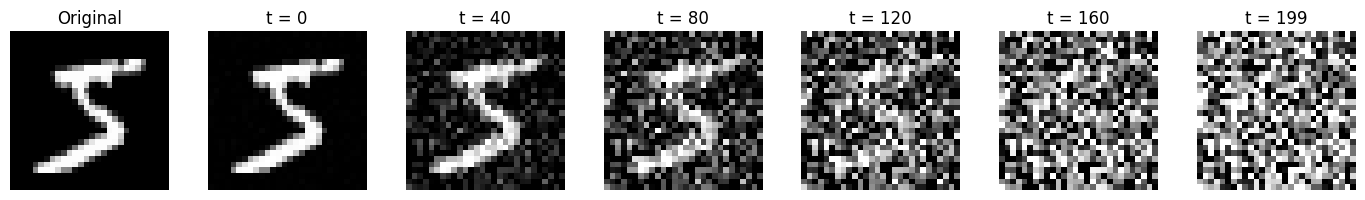

In [35]:
x0, _ = train_dataset[0]
x0 = x0.unsqueeze(0).to(device)

times = [0, 40, 80, 120, 160, 199]
noise = torch.randn_like(x0)

fig, axes = plt.subplots(1, len(times) + 1, figsize=(14, 2))

axes[0].imshow(
    x0[0, 0].cpu(),
    cmap="gray",
    vmin=-1,
    vmax=1
)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, step in zip(axes[1:], times):
    t = torch.tensor([step], device=device)
    xt, _ = add_noise(x0, t, noise)

    ax.imshow(
        xt[0, 0].cpu(),
        cmap="gray",
        vmin=-1,
        vmax=1
    )
    ax.set_title(f"t = {step}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Construire le réseau qui prédit le bruit

Le modèle reçoit deux informations :

1. une image bruitée ;
2. le temps `t`, qui indique son niveau de bruit.

Il prédit le bruit ajouté, avec une sortie de même forme que l’image.

### `TimeEmbedding` : représenter le temps

Le temps est transformé en un vecteur de sinus et de cosinus de différentes fréquences.

Cette représentation permet au réseau de distinguer les niveaux de bruit et d’adapter son traitement.

Deux couches `Linear` transforment ensuite cet encodage en une représentation temporelle apprise.

### `ConvBlock` : traiter l’image et intégrer le temps

Chaque bloc réalise trois opérations :

1. extraire des caractéristiques avec une convolution ;
2. ajouter une projection du vecteur temporel ;
3. poursuivre le traitement avec une deuxième convolution.

La projection temporelle est ajoutée à toutes les positions spatiales, avec une valeur différente par canal.

Les blocs utilisent aussi :

- `GroupNorm` pour normaliser les caractéristiques par groupes de canaux ;
- `SiLU` pour introduire une non-linéarité.

### `SmallUNet` : descendre puis remonter en résolution

La partie descendante réduit la taille des cartes :

$$
28 \times 28 \rightarrow 14 \times 14 \rightarrow 7 \times 7
$$

Elle permet d’extraire des informations à plusieurs échelles.

La partie montante revient à la résolution d’origine :

$$
7 \times 7 \rightarrow 14 \times 14 \rightarrow 28 \times 28
$$

`F.interpolate` agrandit les cartes de caractéristiques.

Les connexions entre descente et remontée, appelées **connexions de saut**, réintroduisent les informations spatiales des premières couches.

`torch.cat(..., dim=1)` concatène ces caractéristiques sur la dimension des canaux.

### Pourquoi une sortie sans sigmoïde ?

La dernière convolution produit un seul canal :

$$
[B, 1, 28, 28]
$$

Cette sortie représente du **bruit**, pas directement des pixels.

Le bruit gaussien pouvant prendre des valeurs positives ou négatives sans borne fixe, on n’utilise ni `Sigmoid` ni `Tanh`.

**Ce réseau apprend donc à répondre à la question : « Quel bruit est présent dans cette image au temps t ? »**

In [36]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2

        frequencies = torch.exp(
            -math.log(10000)
            * torch.arange(
                half,
                device=t.device,
                dtype=torch.float32
            )
            / (half - 1)
        )

        angles = t.float()[:, None] * frequencies[None, :]

        return torch.cat([
            angles.sin(),
            angles.cos()
        ], dim=1)


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()

        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_projection = nn.Linear(time_dim, out_channels)

        self.conv2 = nn.Sequential(
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

    def forward(self, x, time_embedding):
        h = self.conv1(x)

        # Une information temporelle par canal.
        time_features = self.time_projection(time_embedding)
        h = h + time_features[:, :, None, None]

        return self.conv2(h)


class SmallUNet(nn.Module):
    def __init__(self, time_dim=128):
        super().__init__()

        self.time_embedding = nn.Sequential(
            TimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )

        self.encoder1 = ConvBlock(1, 32, time_dim)
        self.encoder2 = ConvBlock(32, 64, time_dim)
        self.middle = ConvBlock(64, 128, time_dim)

        self.pool = nn.AvgPool2d(2)

        self.decoder2 = ConvBlock(128 + 64, 64, time_dim)
        self.decoder1 = ConvBlock(64 + 32, 32, time_dim)

        self.output = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x, t):
        time_embedding = self.time_embedding(t)

        h1 = self.encoder1(x, time_embedding)               # 28 × 28
        h2 = self.encoder2(self.pool(h1), time_embedding)   # 14 × 14
        h = self.middle(self.pool(h2), time_embedding)     # 7 × 7

        h = F.interpolate(
            h, size=h2.shape[-2:], mode="nearest"
        )
        h = self.decoder2(
            torch.cat([h, h2], dim=1),
            time_embedding
        )

        h = F.interpolate(
            h, size=h1.shape[-2:], mode="nearest"
        )
        h = self.decoder1(
            torch.cat([h, h1], dim=1),
            time_embedding
        )

        return self.output(h)


diffusion_model = SmallUNet().to(device)

## 5. Apprendre à prédire le bruit

L’entraînement repose sur une idée simple : ajouter un bruit connu, puis apprendre au réseau à le retrouver.

### Pour chaque lot

1. Déplacer les images sur le bon périphérique.
2. Tirer un temps aléatoire pour chaque image.
3. Créer les images bruitées avec `add_noise`.
4. Prédire le bruit avec le U-Net.
5. Comparer la prédiction au bruit réellement ajouté.
6. Mettre à jour les paramètres.

### La fonction de perte

Le code utilise l’erreur quadratique moyenne :

$$
\mathcal{L}
=
\operatorname{MSE}
\left(
\varepsilon_\theta(x_t,t),
\varepsilon
\right)
$$

- $\varepsilon$ : bruit réellement ajouté ;
- $\varepsilon_\theta(x_t,t)$ : bruit prédit par le réseau.

La cible n’est donc **ni l’étiquette du chiffre ni directement l’image originale**, mais le bruit.

### Pourquoi tirer les temps au hasard ?

Cela permet au modèle d’apprendre à traiter tous les niveaux de bruit sans parcourir les 200 étapes pour chaque image à chaque itération.

### Mettre à jour le modèle

| Instruction | Rôle |
|---|---|
| `optimizer.zero_grad()` | Effacer les anciens gradients |
| `loss.backward()` | Calculer les gradients |
| `clip_grad_norm_(..., 1.0)` | Limiter la norme des gradients pour aider à stabiliser l’entraînement |
| `optimizer.step()` | Ajuster les paramètres avec Adam |

### Suivre l’apprentissage

La perte de chaque lot est pondérée par son nombre d’images, puis divisée par le nombre total d’images traitées.

Comme toutes les images ont la même taille, la valeur affichée correspond à la MSE moyenne sur les éléments parcourus.

`history` conserve une valeur par époque pour tracer une courbe.

**Une perte qui diminue suggère une meilleure prédiction du bruit, mais ne garantit pas à elle seule la qualité des images générées.**

In [37]:
optimizer = torch.optim.Adam(
    diffusion_model.parameters(),
    lr=2e-4
)


def train_diffusion(model, loader, optimizer, epochs=20):
    history = []

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        n_images = 0

        for x, _ in loader:
            x = x.to(device)
            batch_size = x.size(0)

            # Un niveau de bruit différent pour chaque image.
            t = torch.randint(
                0, T,
                (batch_size,),
                device=device
            )

            xt, true_noise = add_noise(x, t)
            predicted_noise = model(xt, t)

            loss = F.mse_loss(predicted_noise, true_noise)

            optimizer.zero_grad()
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            total_loss += loss.item() * batch_size
            n_images += batch_size

        mean_loss = total_loss / n_images
        history.append(mean_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"MSE bruit = {mean_loss:.4f}"
        )

    return history


history = train_diffusion(
    diffusion_model,
    train_loader,
    optimizer,
    epochs=20
)

Epoch 1/20 | MSE bruit = 0.1056
Epoch 2/20 | MSE bruit = 0.0567
Epoch 3/20 | MSE bruit = 0.0518
Epoch 4/20 | MSE bruit = 0.0489
Epoch 5/20 | MSE bruit = 0.0477
Epoch 6/20 | MSE bruit = 0.0462
Epoch 7/20 | MSE bruit = 0.0453
Epoch 8/20 | MSE bruit = 0.0444
Epoch 9/20 | MSE bruit = 0.0440
Epoch 10/20 | MSE bruit = 0.0436
Epoch 11/20 | MSE bruit = 0.0429
Epoch 12/20 | MSE bruit = 0.0424
Epoch 13/20 | MSE bruit = 0.0422
Epoch 14/20 | MSE bruit = 0.0422
Epoch 15/20 | MSE bruit = 0.0418
Epoch 16/20 | MSE bruit = 0.0414
Epoch 17/20 | MSE bruit = 0.0413
Epoch 18/20 | MSE bruit = 0.0410
Epoch 19/20 | MSE bruit = 0.0412
Epoch 20/20 | MSE bruit = 0.0408


# Générer des images par diffusion inverse

Cette fonction produit de nouvelles images MNIST en partant de **bruit aléatoire**, puis en le transformant progressivement en images grâce au modèle entraîné.

```text
Bruit initial → Débruitages successifs → Images générées
```

Sa particularité est de **limiter l’estimation de l’image propre à `[-1, 1]` à chaque étape**, afin de réduire les valeurs extrêmes pendant la génération.

## 1. Préparer le modèle

```python
@torch.no_grad()
def generate_images(model, n_samples=20):
    model.eval()
    model_device = next(model.parameters()).device
```

- `@torch.no_grad()` désactive le suivi des gradients pour toute la fonction : aucun apprentissage n’est effectué.
- `n_samples=20` indique le nombre d’images à générer.
- `model.eval()` active le mode évaluation.
- `next(model.parameters()).device` récupère le périphérique du modèle, afin de placer les calculs sur le même CPU ou GPU.

> `eval()` et `no_grad()` ont des rôles différents : le premier configure les couches, le second désactive le suivi des gradients.

## 2. Retrouver le calendrier de bruit

```python
b = betas.to(model_device)
a = 1.0 - b
abar = torch.cumprod(a, dim=0)
```

Ces coefficients décrivent le bruit ajouté pendant la diffusion :

| Variable | Notation | Rôle |
|---|---|---|
| `b` | $\beta_t$ | Variance du bruit ajouté à une étape |
| `a` | $\alpha_t = 1-\beta_t$ | Facteur de conservation du signal à cette étape |
| `abar` | $\bar{\alpha}_t$ | Produit cumulé des facteurs $\alpha$ |

La fonction `torch.cumprod` calcule les produits successifs.

**Le tableau `betas` doit être celui utilisé pendant l’entraînement.** Il est défini à l’extérieur de la fonction.

```python
abar_prev = torch.cat([
    torch.ones(1, device=model_device),
    abar[:-1]
])
```

`abar_prev` contient les valeurs cumulées de l’étape précédente.

La première valeur vaut `1`, car avant tout ajout de bruit, le signal original est entièrement conservé.

## 3. Préparer les coefficients du processus inverse

```python
posterior_var = (
    b * (1.0 - abar_prev) / (1.0 - abar)
)
```

Cette formule calcule la variance du bruit utilisé lors du retour à l’étape précédente :

$$
\tilde{\beta}_t
=
\beta_t
\frac{1-\bar{\alpha}_{t-1}}
     {1-\bar{\alpha}_t}
$$

Les deux coefficients suivants servent à calculer la moyenne de cette étape :

```python
coef_x0 = (
    b * torch.sqrt(abar_prev) / (1.0 - abar)
)

coef_xt = (
    torch.sqrt(a) * (1.0 - abar_prev) / (1.0 - abar)
)
```

Ils permettent de combiner :

- l’estimation de l’image propre ;
- l’image bruitée actuelle.

Ces expressions viennent du processus gaussien de diffusion, et ne sont pas des poids appris par le réseau.

## 4. Commencer avec du bruit pur

```python
x = torch.randn(
    n_samples, 1, 28, 28,
    device=model_device
)
```

`torch.randn` crée des valeurs tirées indépendamment dans une loi normale de moyenne `0` et de variance `1`.

Le tenseur a pour forme :

```text
[n_samples, 1, 28, 28]
      ↑     ↑   ↑   ↑
   Images Canal Hauteur Largeur
```

Au départ, aucune image réelle n’est fournie au modèle.

> Ce point de départ suppose que le calendrier de diffusion conduit à un état final presque entièrement bruité.

## 5. Parcourir les étapes en sens inverse

```python
for step in reversed(range(len(b))):
```

Avec 200 étapes, la boucle parcourt :

```text
199 → 198 → ... → 1 → 0
```

À chaque passage, `x` est remplacé par une version correspondant à un niveau de bruit inférieur.

```python
t = torch.full(
    (n_samples,),
    step,
    device=model_device,
    dtype=torch.long
)
```

Ce tenseur indique le temps courant au réseau.

Toutes les images du lot sont ici traitées au même temps, mais leurs contenus sont différents.

## 6. Prédire le bruit et estimer l’image propre

```python
predicted_noise = model(x, t)
```

Le modèle prédit le bruit présent dans `x`, en tenant compte du temps `t`.

À partir de la formule de diffusion :

$$
x_t =
\sqrt{\bar{\alpha}_t}\,x_0
+
\sqrt{1-\bar{\alpha}_t}\,\varepsilon
$$

on peut estimer l’image propre :

$$
\hat{x}_0 =
\frac{
x_t-\sqrt{1-\bar{\alpha}_t}\,\hat{\varepsilon}
}{
\sqrt{\bar{\alpha}_t}
}
$$

C’est le calcul suivant :

```python
x0_pred = (
    x - torch.sqrt(1.0 - abar[step]) * predicted_noise
) / torch.sqrt(abar[step])
```

**Le réseau prédit le bruit ; la formule permet ensuite d’en déduire l’image propre estimée.**

## 7. Limiter les valeurs de l’image propre estimée

```python
x0_pred = x0_pred.clamp(-1.0, 1.0)
```

Les images d’entraînement étant normalisées dans `[-1, 1]`, on impose cette même plage à leur estimation.

Cette limitation aide à contrôler les valeurs extrêmes, notamment lorsque l’image courante est très bruitée et que la prédiction du réseau est imparfaite.

> On limite **l’estimation de l’image propre**, pas directement l’image bruitée `x`. Les images bruitées peuvent légitimement dépasser `[-1, 1]`.

## 8. Calculer l’image de l’étape précédente

```python
mean = (
    coef_x0[step] * x0_pred
    + coef_xt[step] * x
)
```

La moyenne de l’étape précédente combine :

- l’image propre estimée `x0_pred` ;
- l’image bruitée actuelle `x`.

Puis on ajoute un bruit contrôlé :

```python
if step > 0:
    x = (
        mean
        + torch.sqrt(posterior_var[step])
        * torch.randn_like(x)
    )
else:
    x = mean
```

- `torch.randn_like(x)` crée un nouveau bruit de même forme que `x`.
- La racine de la variance donne son écart-type.
- À la dernière étape, aucun bruit supplémentaire n’est ajouté.

Le retour vers une image propre est donc **probabiliste**, et non une simple soustraction répétée du bruit prédit.

## 9. Vérifier la stabilité numérique

```python
if not torch.isfinite(x).all():
    raise RuntimeError(
        f"Valeurs non finies pendant la génération, étape {step}"
    )
```

Cette vérification détecte la présence de :

- `NaN` : valeur numérique indéfinie ;
- `+Inf` ou `-Inf` : valeurs infinies.

Si elles apparaissent, la génération s’arrête avec un message indiquant l’étape concernée.

> Cette vérification détecte un problème numérique, mais ne garantit pas que les images soient visuellement de bonne qualité.

## 10. Préparer les images pour l’affichage

```python
return ((x + 1.0) / 2.0).clamp(0, 1).cpu()
```

Cette ligne :

1. transforme les valeurs de `[-1, 1]` vers `[0, 1]` ;
2. limite les éventuels dépassements ;
3. ramène les images sur le CPU pour Matplotlib.

Le résultat conserve la forme :

```text
[n_samples, 1, 28, 28]
```

## À retenir

**Cette fonction transforme du bruit en images en répétant trois opérations : prédire le bruit, estimer une image propre bornée, puis calculer l’étape précédente.**

La limitation de l’image propre estimée améliore la stabilité, mais la qualité finale dépend toujours de l’entraînement du modèle.

In [38]:
@torch.no_grad()
def generate_images(model, n_samples=20):
    model.eval()
    model_device = next(model.parameters()).device

    # Réutiliser exactement le calendrier de l'entraînement.
    b = betas.to(model_device)
    a = 1.0 - b
    abar = torch.cumprod(a, dim=0)

    abar_prev = torch.cat([
        torch.ones(1, device=model_device),
        abar[:-1]
    ])

    # Variance du processus inverse.
    posterior_var = (
        b * (1.0 - abar_prev) / (1.0 - abar)
    )

    # Coefficients de la moyenne conditionnelle q(x_{t-1} | x_t, x_0).
    coef_x0 = (
        b * torch.sqrt(abar_prev) / (1.0 - abar)
    )

    coef_xt = (
        torch.sqrt(a) * (1.0 - abar_prev) / (1.0 - abar)
    )

    x = torch.randn(
        n_samples, 1, 28, 28,
        device=model_device
    )

    for step in reversed(range(len(b))):
        t = torch.full(
            (n_samples,),
            step,
            device=model_device,
            dtype=torch.long
        )

        predicted_noise = model(x, t)

        # Estimation de l'image propre.
        x0_pred = (
            x - torch.sqrt(1.0 - abar[step]) * predicted_noise
        ) / torch.sqrt(abar[step])

        # Les images propres d'entraînement sont dans [-1, 1].
        x0_pred = x0_pred.clamp(-1.0, 1.0)

        # Moyenne de l'étape précédente.
        mean = (
            coef_x0[step] * x0_pred
            + coef_xt[step] * x
        )

        if step > 0:
            x = (
                mean
                + torch.sqrt(posterior_var[step])
                * torch.randn_like(x)
            )
        else:
            x = mean

        if not torch.isfinite(x).all():
            raise RuntimeError(
                f"Valeurs non finies pendant la génération, étape {step}"
            )

    return ((x + 1.0) / 2.0).clamp(0, 1).cpu()

## 7. Visualiser les nouvelles images

`generate_images(..., n_samples=20)` produit vingt images à partir de nouveaux tirages aléatoires.

Elles sont affichées dans une grille de deux lignes et dix colonnes.

### Parcourir la grille

- `axes.flat` parcourt les vingt sous-graphiques.
- `enumerate` fournit l’indice de l’image et la case correspondante.
- `samples[i, 0]` sélectionne le canal unique de l’image `i`, sous forme d’une matrice `[28, 28]`.

### Afficher les pixels

- `cmap="gray"` utilise les niveaux de gris.
- `vmin=0` et `vmax=1` imposent une échelle commune à toutes les images.
- `axis("off")` masque les graduations.
- `suptitle` ajoute un titre global.
- `tight_layout` ajuste les espacements.

### Que faut-il observer ?

- Les formes ressemblent-elles à des chiffres ?
- Les traits sont-ils cohérents ?
- Les images sont-elles diversifiées ?
- Certaines générations sont-elles floues ou ambiguës ?

**Le modèle n’est pas conditionné par une classe : on ne choisit pas quel chiffre sera généré.**

Les images changent généralement à chaque exécution, car le processus utilise des tirages aléatoires.

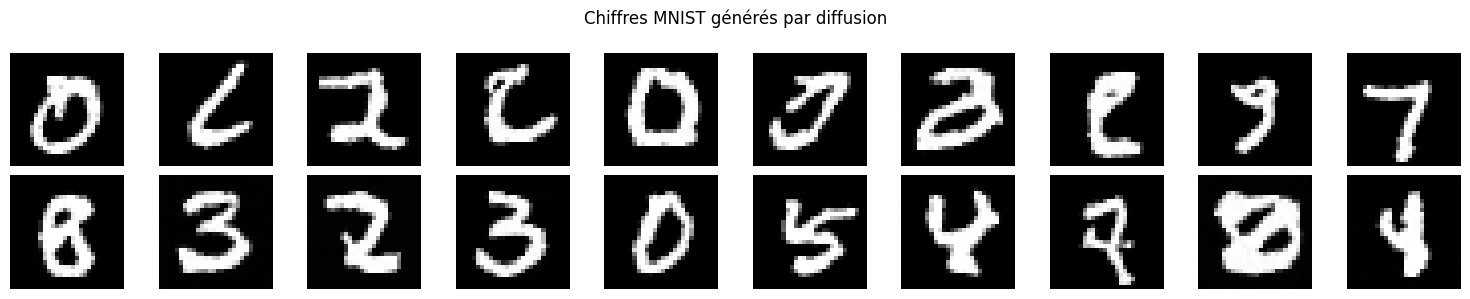

In [ ]:
samples = generate_images(diffusion_model, n_samples=20)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        samples[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.axis("off")

plt.suptitle("Chiffres MNIST générés par diffusion")
plt.tight_layout()
plt.show()

## 8. Observer l’évolution de la perte

Ce bloc trace les valeurs enregistrées dans `history`.

- **Axe horizontal** : numéro de l’époque.
- **Axe vertical** : MSE moyenne entre le bruit prédit et le bruit réellement ajouté.

### Comment lire la courbe ?

- **Tendance à la baisse** : le réseau améliore sa prédiction du bruit sur les données d’entraînement.
- **Plateau** : les progrès deviennent faibles avec les réglages actuels.
- **Fluctuations** : elles peuvent provenir des lots, des temps et des bruits tirés au hasard.
- **Hausse persistante ou valeurs non finies** : elles peuvent signaler une instabilité à examiner.

La perte rassemble des situations de difficulté différente, puisque les niveaux de bruit sont échantillonnés aléatoirement.

> Il s’agit d’une perte d’entraînement, pas d’une mesure calculée sur un jeu de validation.

**Pour juger le modèle, il faut compléter la courbe par l’examen de la qualité et de la diversité des images générées.**

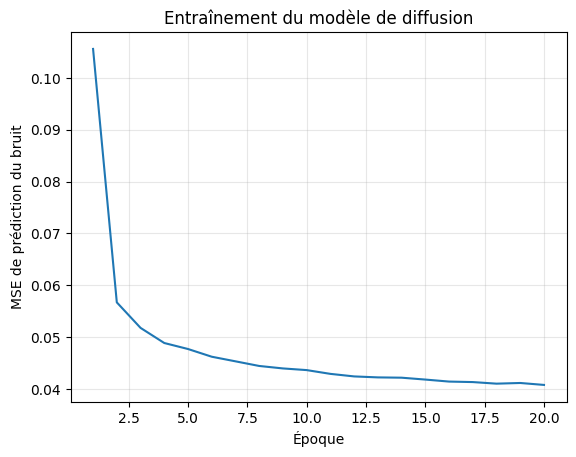

In [39]:
plt.plot(range(1, len(history) + 1), history)
plt.xlabel("Époque")
plt.ylabel("MSE de prédiction du bruit")
plt.title("Entraînement du modèle de diffusion")
plt.grid(alpha=0.3)
plt.show()